# Week 5 - Part F (bonus): a normalized map on real data

**COVID-19 deaths per 100,000 people, cumulative to 31 December 2022, by country.** A real count (confirmed deaths reported to WHO) divided by a real denominator (UN 2022 population), on real boundaries (Natural Earth), five classes, an equal-area projection and a full caption.

Sources, all downloaded **24 October 2026** (`get_data.py` re-creates both files):
- **Deaths:** WHO COVID-19 dashboard counts, as republished by Our World in Data, `covid-19-data/public/data/cases_deaths/full_data.csv`, column `total_deaths` on 2022-12-31.
- **Population:** UN World Population Prospects 2022, as packaged by Our World in Data, `covid-19-data/scripts/input/un/population_latest.csv`.
- **Boundaries:** Natural Earth 1:110m Admin 0 - Countries, **release v5.1.2** (`natural-earth-vector` repository). Natural Earth draws *de facto* boundaries. Kashmir, for example, is split along the Line of Control, which matches neither Pakistan's nor India's official maps. At this scale that's a political choice made by the boundary file, and I'm stating it rather than hiding it (slide 48).

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Polygon as MplPolygon
from matplotlib.collections import PatchCollection

try:
    HERE = Path(__file__).resolve().parent
    IN_NOTEBOOK = False
except NameError:
    HERE = Path.cwd()
    IN_NOTEBOOK = True
sys.path.insert(0, str(HERE.parent))           # geolib.py / vizlib.py live in week5/


def show():
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close("all")


import geolib as gl
from vizlib import PALETTE, save_fig, style_defaults

style_defaults()
INK, SOFT, GREY = PALETTE["ink"], PALETTE["ink_soft"], PALETTE["muted"]
DATA = HERE / "data"
LAT_TS = 30.0                                 # Behrmann: cylindrical equal-area with true scale at 30°

## Load, join, and count what doesn't join

In [2]:
df = pd.read_csv(DATA / "covid_deaths_2022.csv")
with open(DATA / "ne_110m_admin_0_countries_v5.1.2.geojson") as fh:
    ne = json.load(fh)["features"]


def ne_key(p):
    return p["ISO_A3_EH"] if p["ISO_A3_EH"] != "-99" else p["ADM0_A3"]


shapes = {}                                   # key -> (name, [rings])
for f in ne:
    p, geom = f["properties"], f["geometry"]
    polys = geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]
    shapes[ne_key(p)] = (p["NAME"], [poly[0] for poly in polys])
print(f"{len(df)} countries/territories with deaths + population; {len(shapes)} Natural Earth polygons")

dropped = ["ATA"]                              # Antarctica: no population, and it would fill a fifth of an equal-area map
geo_keys = set(shapes) - set(dropped)
no_poly = df[~df.iso3.isin(geo_keys)]
no_data = sorted(shapes[k][0] for k in geo_keys - set(df.iso3))
print(f"rows with no polygon at 1:110m: {len(no_poly)} (small islands and territories, {no_poly.population.sum() / 1e6:.1f} M people), e.g. {no_poly.location.head(6).tolist()}")
print(f"polygons with no row: {len(no_data)} -> {no_data}")

233 countries/territories with deaths + population; 177 Natural Earth polygons
rows with no polygon at 1:110m: 62 (small islands and territories, 17.0 M people), e.g. ['Aruba', 'Anguilla', 'Andorra', 'American Samoa', 'Antigua and Barbuda', 'Bonaire Sint Eustatius and Saba']
polygons with no row: 5 -> ['Fr. S. Antarctic Lands', 'N. Cyprus', 'Somaliland', 'Taiwan', 'W. Sahara']


## Normalize, and say what is excluded

In [3]:
df["rate"] = df.deaths_to_2022_12_31 / df.population * 1e5
zero = df[(df.deaths_to_2022_12_31 == 0) & df.iso3.isin(geo_keys)]
print(f"countries reporting ZERO deaths across 2020-2022: {zero.location.tolist()}  (population {zero.population.sum() / 1e6:.1f} M)")
mapped = df[df.iso3.isin(geo_keys) & (df.deaths_to_2022_12_31 > 0)].copy()
print(f"mapped: {len(mapped)} countries, {mapped.population.sum() / 1e9:.2f} bn people, {mapped.deaths_to_2022_12_31.sum() / 1e6:.2f} M reported deaths")

for sch in ["equal", "quantile", "natural"]:
    e = gl.breaks(mapped.rate, sch, 5)
    print(f"{sch:>9s}: breaks {[round(float(x)) for x in e]}  GVF {gl.gvf(mapped.rate, e):.3f}  counts {np.bincount(gl.class_of(mapped.rate, e), minlength=5).tolist()}")
EDGES = gl.breaks(mapped.rate, "natural", 5)
GVF = gl.gvf(mapped.rate, EDGES)

by_count = mapped.nlargest(5, "deaths_to_2022_12_31")
by_rate = mapped.nlargest(5, "rate")
print("\ntop 5 by COUNT:", [(r.location, f"{r.deaths_to_2022_12_31:,}", f"{r.rate:.0f}/100k") for r in by_count.itertuples()])
print("top 5 by RATE: ", [(r.location, f"{r.deaths_to_2022_12_31:,}", f"{r.rate:.0f}/100k") for r in by_rate.itertuples()])
print(f"r(deaths, population) across mapped countries: {mapped.deaths_to_2022_12_31.corr(mapped.population):+.2f}")
print(f"overlap of the two top-5 lists: {len(set(by_count.iso3) & set(by_rate.iso3))}")
pak = mapped.set_index("iso3").loc["PAK"]
pak_rank = int(mapped.rate.rank(ascending=False)[mapped.iso3 == "PAK"].iloc[0])
print(f"Pakistan: {pak.deaths_to_2022_12_31:,} deaths, {pak.rate:.1f} per 100k (rank {pak_rank} of {len(mapped)}, class {int(gl.class_of([pak.rate], gl.breaks(mapped.rate, 'natural', 5))[0]) + 1} of 5)")

countries reporting ZERO deaths across 2020-2022: ['Falkland Islands', 'North Korea', 'Turkmenistan']  (population 32.5 M)
mapped: 168 countries, 7.90 bn people, 6.68 M reported deaths
    equal: breaks [0, 128, 256, 384, 512, 640]  GVF 0.925  counts [106, 31, 21, 8, 2]
 quantile: breaks [0, 8, 37, 120, 247, 640]  GVF 0.887  counts [34, 33, 34, 33, 34]
  natural: breaks [0, 58, 140, 241, 379, 640]  GVF 0.957  counts [79, 30, 25, 24, 10]

top 5 by COUNT: [('United States', '1,079,976', '319/100k'), ('Brazil', '692,743', '322/100k'), ('India', '530,693', '37/100k'), ('Russia', '393,383', '272/100k'), ('Mexico', '331,322', '260/100k')]
top 5 by RATE:  [('Peru', '218,007', '640/100k'), ('Bulgaria', '38,036', '561/100k'), ('Bosnia and Herzegovina', '16,222', '502/100k'), ('Hungary', '48,439', '486/100k'), ('North Macedonia', '9,876', '472/100k')]
r(deaths, population) across mapped countries: +0.42
overlap of the two top-5 lists: 0


Pakistan: 30,635 deaths, 13.0 per 100k (rank 124 of 168, class 1 of 5)


**Exclusions, with rule and count.**
- **Antarctica** dropped (no population). It would otherwise be the largest single patch on an equal-area map.
- **Rule: a country that reported zero deaths across all of 2020-2022 is shown as "no usable report", not as the lowest class.** A zero there means no reporting, not no deaths. Count and names printed above.
- **No data**: territories Natural Earth draws separately but WHO does not report separately (printed above), drawn hatched.
- **Too small to draw at 1:110m**: the small islands and territories printed above. They're in the data but have no polygon at this scale.

**Scheme: natural breaks (Jenks), 5 classes.** It has the highest goodness of variance fit of the three schemes (printed above). The rates are skewed, from near 0 to 640 per 100,000, so equal interval would dump most countries into the bottom class. Quantile would draw equal-sized groups through a long tail.

**Projection: Behrmann (cylindrical equal-area, true scale at 30°)**, from `geolib.equal_area_xy`. Colour over area makes area the encoding, so every country's ink has to be proportional to its land. On Web Mercator, Russia and Canada would be inflated many times over.

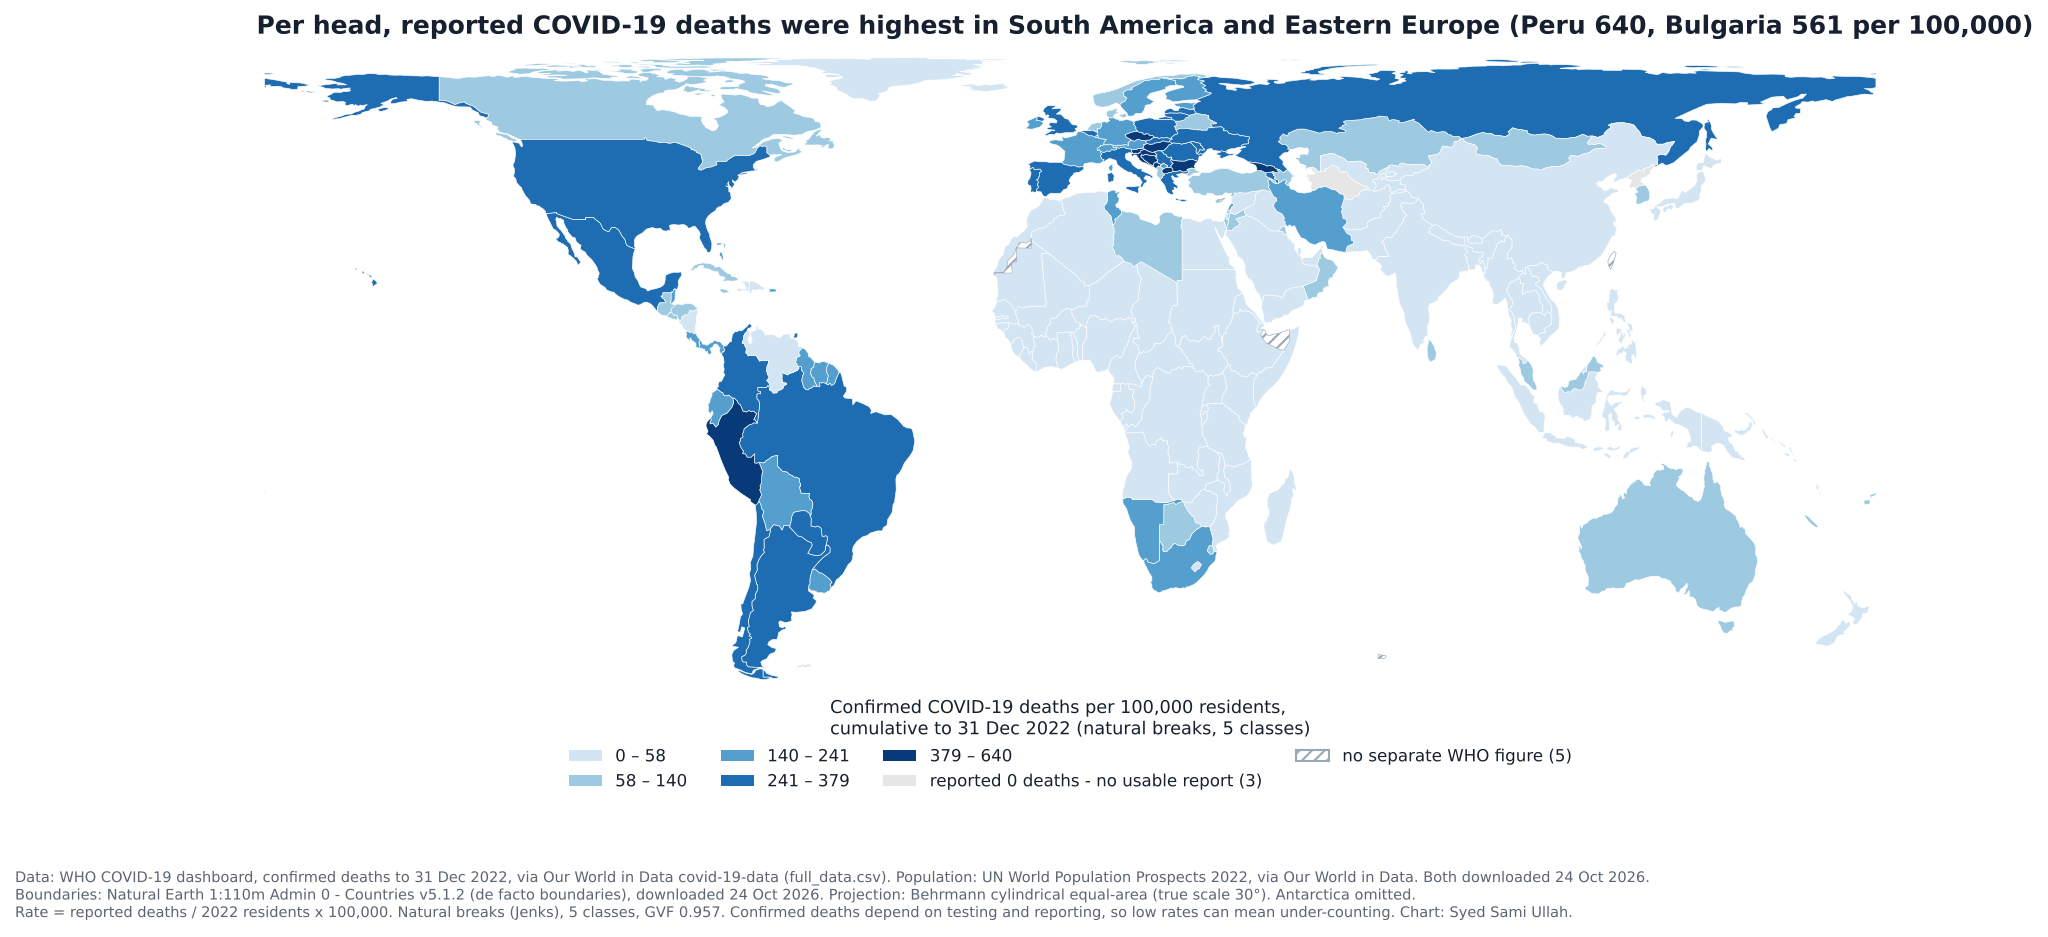

In [4]:
def project(ring):
    x, y = gl.equal_area_xy([p[0] for p in ring], [p[1] for p in ring], lat_ts=LAT_TS)
    return np.column_stack([x, y])


rate_of = dict(zip(mapped.iso3, mapped.rate))
cm = plt.get_cmap(PALETTE["sequential"])
shades = [cm(0.18 + 0.78 * c / 4) for c in range(5)]
zero_keys = set(zero.iso3)

fig, ax = plt.subplots(figsize=(14, 6.3))
fills, hatched, unrep = [], [], []
for key, (name, rings) in shapes.items():
    if key in dropped:
        continue
    for ring in rings:
        patch = MplPolygon(project(ring), closed=True)
        if key in rate_of:
            fills.append((patch, shades[int(gl.class_of([rate_of[key]], EDGES)[0])]))
        elif key in zero_keys:
            unrep.append(patch)
        else:
            hatched.append(patch)
ax.add_collection(PatchCollection([p for p, _ in fills], facecolors=[c for _, c in fills], edgecolors="white", linewidths=0.3))
ax.add_collection(PatchCollection(unrep, facecolors="#E6E6E6", edgecolors="white", linewidths=0.3))
ax.add_collection(PatchCollection(hatched, facecolors="white", edgecolors=GREY, hatch="////", linewidths=0.3))
ax.autoscale_view()
ax.set_aspect("equal")
ax.set_axis_off()
ax.margins(0.005)

labels = [f"{EDGES[c]:,.0f} – {EDGES[c + 1]:,.0f}" for c in range(5)]
handles = [Patch(facecolor=shades[c], label=labels[c]) for c in range(5)]
handles += [Patch(facecolor="#E6E6E6", label=f"reported 0 deaths - no usable report ({len(zero_keys)})"),
            Patch(facecolor="white", edgecolor=GREY, hatch="////", label=f"no separate WHO figure ({len(no_data)})")]
ax.legend(handles=handles, title="Confirmed COVID-19 deaths per 100,000 residents,\ncumulative to 31 Dec 2022 (natural breaks, 5 classes)",
          loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=4, fontsize=8, title_fontsize=8.5, frameon=False)
top_txt = ", ".join(f"{r.location} {r.rate:.0f}" for r in by_rate.head(2).itertuples())
ax.set_title(f"Per head, reported COVID-19 deaths were highest in South America and Eastern Europe ({top_txt} per 100,000)",
             fontsize=12)
note = ("Data: WHO COVID-19 dashboard, confirmed deaths to 31 Dec 2022, via Our World in Data covid-19-data (full_data.csv). Population: UN World Population Prospects 2022, via Our World in Data. "
        "Both downloaded 24 Oct 2026.\n"
        "Boundaries: Natural Earth 1:110m Admin 0 - Countries v5.1.2 (de facto boundaries), downloaded 24 Oct 2026. Projection: Behrmann cylindrical equal-area (true scale 30°). Antarctica omitted.\n"
        f"Rate = reported deaths / 2022 residents x 100,000. Natural breaks (Jenks), 5 classes, GVF {GVF:.3f}. Confirmed deaths depend on testing and reporting, so low rates can mean under-counting. "
        "Chart: Syed Sami Ullah.")
save_fig(fig, HERE / "partF_map.png", note=note)
show()

**What this chart shows.** Per resident, the darkest countries are in South America (Peru by a long way) and Eastern Europe, with the US and much of Western Europe one class below. Most of Africa and South and East Asia are in the lightest class. That partly reflects real differences (age structure) and partly reporting: confirmed deaths need a test and a death certificate. Pakistan sits in the bottom class (printed above).

**What the raw-count version would have shown:** the five countries with the most reported deaths (the US, Brazil, India, Russia, Mexico) would have been darkest, because they're among the most populous. India's 530,693 deaths are only 37 per 100,000, but on a count map it would look like one of the worst-hit countries in the world, while on a five-class natural-breaks count map Peru, the worst per head, would sit in the second-lightest class and Bulgaria (561 per 100,000) in the lightest.